# Histogram reproduction — Asimov vs median of toys

**What this notebook does.** Reproduces the histogram-analysis half of the NSBI-shortcomings study.
It bins the off-shell $gg\to ZZ\to 4\ell$ events in $m_{4\ell}$, builds the extended-Poisson
negative-log-likelihood (NLL) scan in the signal strength $\mu$ for **(a)** the Asimov dataset and
**(b)** 200 toy pseudo-experiments, and checks — at 1, 10, 100 and 1000 fb$^{-1}$ — whether the
Asimov scan equals the median of the toys (the *Asimov property*).

**Result.** The property holds at every luminosity: the median-of-toys curve sits on top of the
Asimov curve (see *Main result* below). This is the histogram baseline the NSBI analysis is compared
against — NSBI is expected to *break* this at 1–10 fb$^{-1}$.

**How to use it.** Run top to bottom (~1–2 min inside the Apptainer container). Everything you would
normally tweak is in the **Parameters** cell (luminosities, binning, number of toys, $\mu$ grid),
and the plotting cells are separate from the analysis so you can restyle the figures and re-run just
those cells.

> **Engine.** This notebook only *calls* the analysis code in the `asimov-aymptotics-check` sub-repo
> (`physics`, `stats` packages) — it does not reimplement any physics. Companion write-up:
> `docs/hist-reproduction.md`; theory primer: `docs/notes/sbi_foundations.md`.
>
> **Run it** from the container: `apptainer exec --nv --env PYTHONNOUSERSITE=1 asimov-aymptotics-check/ml4fp-sbi-tutorial.sif jupyter lab` (or execute headlessly). `PYTHONNOUSERSITE=1` keeps stray `~/.local` packages from shadowing the container.

## 1. Imports and engine path

In [2]:
import os, sys, json
import numpy as np
import torch
import hist
import matplotlib.pyplot as plt

# Point Python at Tei's analysis packages (physics/, stats/) inside the sub-repo.
ROOT    = os.environ.get('SBI_ROOT', '/project/atlas/Users/mfernand/SBI_shortcomings')
SUBREPO = os.path.join(ROOT, 'asimov-aymptotics-check')
if SUBREPO not in sys.path:
    sys.path.insert(0, SUBREPO)

from physics.simulation import mcfm, toys           # data loader + toy generator (the engine)
from physics.hstar import sigstr                     # per-event mu reweighting
from stats.binned import poisson_log_likelihood_scan, poisson_log_likelihood_scan_toys

torch.set_default_dtype(torch.float32)
print('engine:', SUBREPO)

engine: /project/atlas/Users/mfernand/SBI_shortcomings/asimov-aymptotics-check


## 2. Parameters

Everything you might want to change lives here. Defaults reproduce the committed study.

In [3]:
# ---- adjust here --------------------------------------------------------------
DATA_DIR = os.environ.get('DATASET_DIR', os.path.join(ROOT, 'data/zz4l/ggzz4l_sm'))
LUMIS    = [1., 10., 100., 1000.]         # luminosities to scan [fb^-1]
N_ROWS   = int(3e5)                        # events read from the SBI CSV
N_TOYS   = 200                             # toy pseudo-experiments per luminosity
SEED     = 42                              # toy random seed
MU_SCAN  = torch.linspace(0.0, 4.0, 101)   # signal-strength grid
N_BINS, M4L_LO, M4L_HI = 10, 180, 1000     # m4l log-binning [GeV]
# -------------------------------------------------------------------------------

m4l_axis = hist.axis.Regular(N_BINS, M4L_LO, M4L_HI, transform=hist.axis.transform.log)
features_4l = ['l1_pt','l1_eta','l1_phi','l1_energy','l2_pt','l2_eta','l2_phi','l2_energy',
               'l3_pt','l3_eta','l3_phi','l3_energy','l4_pt','l4_eta','l4_phi','l4_energy','4l_mass']
mu_np = MU_SCAN.numpy()

## 3. Load the events (once)

The cross-section JSON stores `[flavour-count, k-factor, sigma_raw]` per component; `np.prod` gives
the usable cross-section in fb, and `mcfm.from_csv` normalises the sum of event weights to it.
**Luminosity is not applied here** — it enters only as a multiplier at histogram-fill time, so the
same events serve every luminosity in `LUMIS`.

In [4]:
with open(os.path.join(DATA_DIR, 'ggzz4l_xs.json')) as f:
    xs = json.load(f)
xs_sbi_sm = np.prod(xs['sbi'])

events_sbi = mcfm.from_csv(file_path=os.path.join(DATA_DIR, 'ggzz4l_sbi.csv'),
                           kinematics=features_4l, cross_section=xs_sbi_sm, n_rows=N_ROWS)
m4l = events_sbi.kinematics['4l_mass'].values
print(f'loaded {len(m4l):,} events;  sum of SM weights = {events_sbi.weights.sum():.4f} fb  (= cross-section)')

loaded 300,000 events;  sum of SM weights = 5.6565 fb  (= cross-section)


## 4. Per-event weights (luminosity-independent)

`sigstr.scale` reweights the single SBI sample to any signal strength $\mu$ via the stored matrix
elements: $w(\mu)=w_{\rm sm}\,(\mu\,{\rm msq}_S+\sqrt{\mu}\,{\rm msq}_I+{\rm msq}_B)/{\rm msq}_{\rm SBI}$.
We compute the SM point ($\mu=1$) and the whole $\mu$ grid once. Because a histogram bin's content
is *linear* in the weights, the Asimov and expected-scan histograms at luminosity $L$ are simply
$L\times$ their unit-luminosity values — so the expensive 101-point fill is done a single time.

In [5]:
w_sm,   _ = sigstr.scale(events_sbi, signal_strength=1.0,     ignore_interference=False)   # (N,)
w_scan, _ = sigstr.scale(events_sbi, signal_strength=MU_SCAN, ignore_interference=False)   # (N, 101)

def fill(weights):
    h = hist.Hist(m4l_axis)
    h.fill(m4l, weight=np.asarray(weights))
    return h.values()

nu_asimov_unit = fill(w_sm)                                                          # (10,)  at L=1
nu_exp_unit    = np.stack([fill(w_scan[:, m]) for m in range(w_scan.shape[1])], 1)   # (10,101) at L=1
print('unit-luminosity Asimov m4l histogram (events / fb):')
print(np.round(nu_asimov_unit, 4))

unit-luminosity Asimov m4l histogram (events / fb):
[1.8545 1.7091 1.0148 0.5328 0.2759 0.1406 0.0723 0.0322 0.0154 0.0059]


## 5. Luminosity loop: Asimov + toys + NLL scans

For each luminosity $L$: scale the (linear) Asimov and expected histograms by $L$; throw `N_TOYS`
Poisson pseudo-datasets ($w_{\rm toy}\sim{\rm Poisson}(w_{\rm sm}L)$ per event) and histogram them;
then evaluate the binned extended-Poisson NLL scan
$$\mathrm{NLL}(\mu) = -2\sum_{\rm bins}\big[\,n\,\ln\nu(\mu)-\nu(\mu)-\ln n!\,\big].$$
The rate term $-\nu(\mu)$ is included automatically (the histogram likelihood is a full extended
likelihood), which is exactly the piece the NSBI notebook is missing.

In [6]:
results = {}
for L in LUMIS:
    nu_asimov = nu_asimov_unit * L                                                    # (10,)
    nu_exp    = nu_exp_unit * L                                                        # (10,101)

    nu_toys    = toys.generate(w_sm * L, n_toys=N_TOYS, random_state=SEED)             # (N_TOYS, N)
    n_obs_toys = torch.tensor(np.stack([fill(nu_toys[i, :]) for i in range(N_TOYS)], 1))  # (10,N_TOYS)

    nll_asimov = -2 * poisson_log_likelihood_scan(nu_asimov, nu_exp)                   # (101,)
    nll_toys   = -2 * poisson_log_likelihood_scan_toys(n_obs_toys, nu_exp)             # (101,N_TOYS)
    results[L] = dict(nll_asimov=nll_asimov, nll_toys=nll_toys, nu_asimov=nu_asimov)
    print(f'{L:>7.0f} fb^-1 :  Asimov mu_hat = {MU_SCAN[torch.argmin(nll_asimov)]:.3f}')

/project/atlas/Users/mfernand/SBI_shortcomings/asimov-aymptotics-check/physics/simulation/toys.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  weights = torch.tensor(nu, dtype=torch.float64)


      1 fb^-1 :  Asimov mu_hat = 1.000
     10 fb^-1 :  Asimov mu_hat = 1.000
    100 fb^-1 :  Asimov mu_hat = 1.000
   1000 fb^-1 :  Asimov mu_hat = 1.000


## 6. Main result — Asimov vs median of toys

Four luminosities across, **two band conventions down**. Both rows show the same Asimov curve
(dashed) and summarise the same 200 toy scans — they differ only in *how* the toy ensemble is
reduced to a median + a $\pm1\sigma$ band, and that choice changes the picture a lot.

**Row 1 — per-toy $\Delta$** (the convention adopted 2026-07-13, `docs/dimensionality-study.md`).
Each toy is min-subtracted *on its own* before the ensemble is summarised, i.e. every toy contributes
the $-2\Delta\ln L$ curve a real experiment would quote. The band is $\ge 0$ by construction, and
tight.

**Row 2 — common offset** (Tei's slide 6). The *raw* toy curves are shifted by a single constant (the
minimum of the median curve), so the vertical spread of the likelihood *value* survives and **the band
goes negative** — which is exactly what his slide-5 caveat means by *"the y-axis is not consistent
between toys; some toy curves should go negative w.r.t. the nominal Asimov curve."*

In both rows the median line is the **50% quantile of the very curves the band brackets**, so line and
band are one statistic. (An earlier version of this cell mixed them — a per-toy-$\Delta$ band around a
median-of-*raw* line — which put the line outside its own band at 13% of the $\mu$ points at
1 fb$^{-1}$.) `np.median` throughout: `torch.median` takes the lower middle element at even toy counts
and was retired on 2026-07-13.

> ### Read row 1 carefully: the $\Delta$-median curve has a pedestal
>
> In row 1 the median sits visibly **above** the Asimov, and it does so *by construction* — this is not
> the histogram failing.
>
> Min-subtraction is a **per-toy** operation: toy $i$ is shifted by *its own* minimum, which sits at
> *its own* $\hat\mu_i$. Every toy is shifted by a *different, random* amount, so the shift does not
> commute with the median and the resulting curve is not a likelihood curve at all. The consequence is
> forced: at $\mu = \mu_{\rm true}$ each toy has $\Delta_i \ge 0$, with equality only if that toy's
> $\hat\mu_i$ landed *exactly* on the truth — which no toy does. So
> $\mathrm{med}_i\,\Delta_i(\mu_{\rm true}) > 0$ strictly, while the Asimov curve is 0 there by
> definition. **A quantity that is positive for every toy cannot have a median of zero**, so the
> $\Delta$-median curve can never lie on the Asimov curve. That argument is an inequality — it needs no
> asymptotics and no model.
>
> **How big is the pedestal? Asymptotically, 0.455 — but we are not there.** If the toys were
> asymptotic ($\hat\mu \sim \mathcal{N}(\mu_{\rm true}, \sigma)$, parabolic curves) then
> $\Delta_i(\mu_{\rm true}) \sim \chi^2_1$ and the pedestal would be $\mathrm{med}(\chi^2_1) = 0.455$,
> flat in luminosity. **Our measured `ped(D)` does not do that:**
>
> | | 1 fb⁻¹ | 10 fb⁻¹ | 100 fb⁻¹ | 1000 fb⁻¹ | asymptotic |
> |---|---|---|---|---|---|
> | `ped(D)` | 0.027 | 0.145 | 0.458 | 0.662 | 0.455 (flat) |
> | `ratio(D)` | — | — | 0.990 | 1.052 | 1.185 |
>
> It rises monotonically and *overshoots*, so the 0.458 at 100 fb⁻¹ is a curve crossing 0.455 on its way
> up, **not** convergence to it. The width tells the same story: the asymptotic model predicts the
> $\Delta$-median curve should be **18% wider** than the Asimov (ratio 1.185 — verified by direct
> simulation of parabolic toys), and we measure 0.99–1.05. **Neither asymptotic prediction is reproduced,
> at any luminosity we test, including 1000 fb⁻¹.**
>
> That is not a bug — it is the project's own thesis showing up in its control channel: these toys are
> **not asymptotic**, and §10 says why (the $\hat\mu$ distribution is bimodal, sitting on the two fold
> branches, not Gaussian). ⚠ **Open:** why the width ratio lands at ~1 rather than the asymptotic 1.185
> is *not* explained here. Do not quote 0.455 as a validated prediction of this analysis.
>
> **Consequence for the convention (this part is robust — it rests on the inequality, not the value):**
> the $\Delta$ convention is the right one for *widths* (it is what an experiment quotes), but the
> *overlay* "Asimov = median of toys" can only be read in **row 2**. Row 2 is the panel that tests the
> Asimov property; row 1 is the panel that measures its width. The 2026-07-13 convention decision did not
> draw this distinction — it belongs in the Tei message (plan item 7).

Dotted line = the $-2\Delta\ln L = 1$ (68%) level. This is the plotting cell; restyle freely and re-run
just this cell.

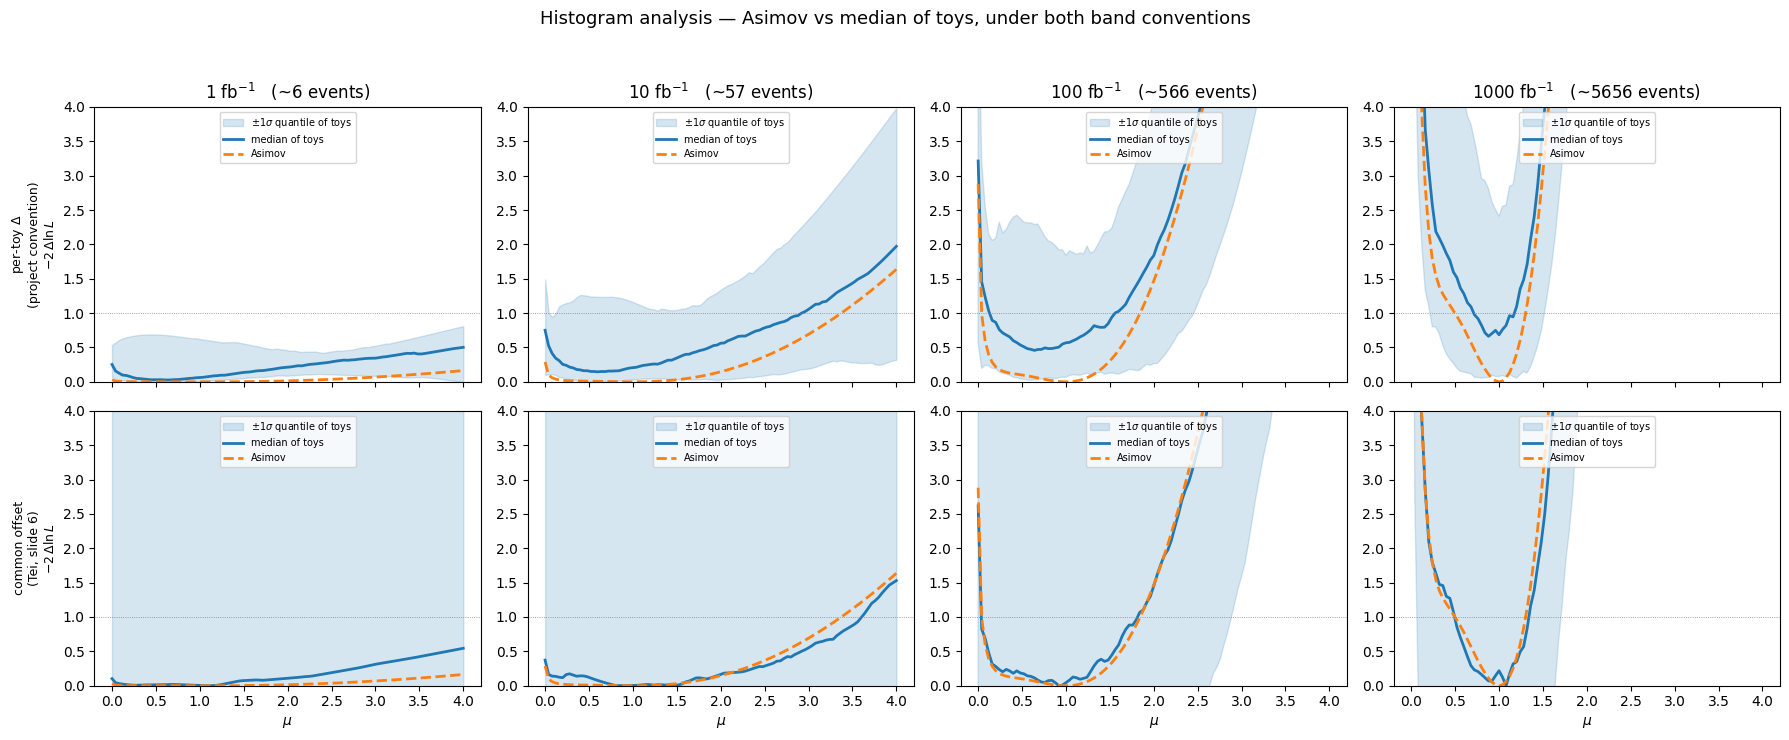

In [11]:
def toy_summary(nll_toys, convention):
    """Reduce the (n_mu, n_toys) toy scans to (lo, median, hi) under one convention.

    'delta'  : min-subtract every toy on its own, then take quantiles  -> band >= 0.
    'offset' : shift all raw toys by one constant, then take quantiles -> band can go negative.
    In both cases the median returned IS the 50% quantile of the curves the band brackets.
    """
    T = np.asarray(nll_toys)                                    # (n_mu, n_toys)
    if convention == 'delta':
        C = T - T.min(axis=0)                                   # each toy reports its own Delta
    elif convention == 'offset':
        C = T - np.median(T, axis=1).min()                      # one common constant (Tei, slide 6)
    else:
        raise ValueError(convention)
    lo, med, hi = np.quantile(C, [0.16, 0.50, 0.84], axis=1)
    return lo, med, hi

CONVENTIONS = [('delta',  r'per-toy $\Delta$' + '\n(project convention)'),
               ('offset', 'common offset\n(Tei, slide 6)')]

fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), sharex=True)
for i, (conv, row_label) in enumerate(CONVENTIONS):
    for j, L in enumerate(LUMIS):
        r  = results[L]
        da = (r['nll_asimov'] - r['nll_asimov'].min()).numpy()
        lo, med, hi = toy_summary(r['nll_toys'], conv)

        ax = axes[i, j]
        ax.fill_between(mu_np, lo, hi, alpha=0.18, color='C0', label=r'$\pm1\sigma$ quantile of toys')
        ax.plot(mu_np, med, '-',  color='C0', lw=2, label='median of toys')
        ax.plot(mu_np, da,  '--', color='C1', lw=2, label='Asimov')
        ax.set_ylim(0,4)
        ax.axhline(0.0, color='grey', lw=0.6)
        ax.axhline(1.0, color='grey', lw=0.6, ls=':')           # the 68% (Delta = 1) level
        if i == 0:
            ax.set_title(f'{L:.0f} fb$^{{-1}}$   (~{5.656*L:.0f} events)')
        if j == 0:
            ax.set_ylabel(row_label + '\n' + r'$-2\,\Delta\ln L$', fontsize=9)
        if i == len(CONVENTIONS) - 1:
            ax.set_xlabel(r'$\mu$')
        ax.legend(fontsize=7, loc='upper center')
# no set_ylim: row 2's band must be free to go below zero, which is the whole point of it
fig.suptitle('Histogram analysis — Asimov vs median of toys, under both band conventions', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 7. Diagnostics at the lowest luminosity

Left: the Asimov $m_{4\ell}$ spectrum (the steeply falling off-shell tail). Right: all 200 individual
toy scans (thin) with the Asimov overlaid — this is what the median in the panel above summarises.

<>:6: SyntaxWarning: invalid escape sequence '\e'
<>:6: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_3316812/1195400171.py:6: SyntaxWarning: invalid escape sequence '\e'
  axL.set_title(f'Asimov $m_{{4\ell}}$ spectrum at {L0:.0f} fb$^{{-1}}$')


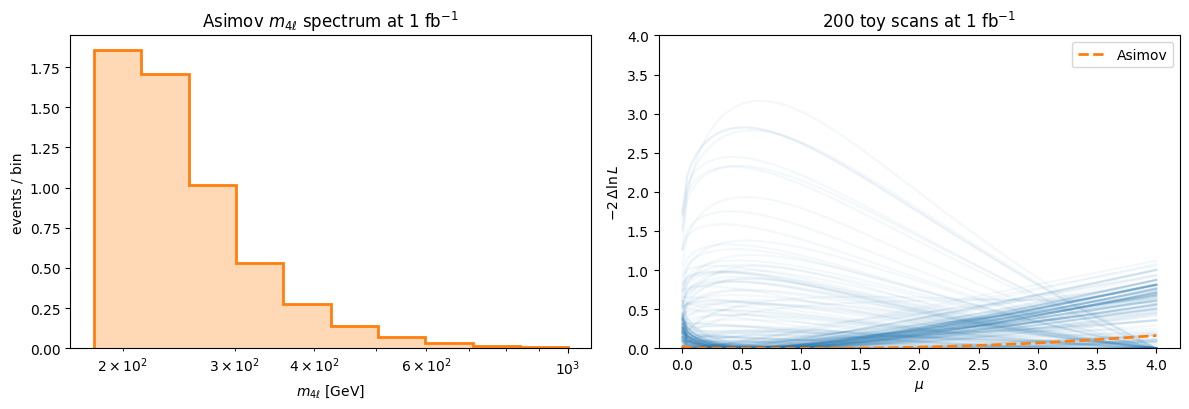

In [7]:
L0 = LUMIS[0]; r = results[L0]; edges = m4l_axis.edges
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4.2))
axL.stairs(r['nu_asimov'], edges, color='C1', lw=2, fill=True, alpha=0.3)
axL.stairs(r['nu_asimov'], edges, color='C1', lw=2)
axL.set_xscale('log'); axL.set_xlabel(r'$m_{4\ell}$ [GeV]'); axL.set_ylabel('events / bin')
axL.set_title(f'Asimov $m_{{4\ell}}$ spectrum at {L0:.0f} fb$^{{-1}}$')
for i in range(r['nll_toys'].shape[1]):
    axR.plot(mu_np, (r['nll_toys'][:, i] - r['nll_toys'][:, i].min()).numpy(), color='C0', alpha=0.05)
axR.plot(mu_np, (r['nll_asimov'] - r['nll_asimov'].min()).numpy(), '--', color='C1', lw=2, label='Asimov')
axR.set_xlabel(r'$\mu$'); axR.set_ylabel(r'$-2\,\Delta\ln L$'); axR.set_ylim(0, 4)
axR.set_title(f'200 toy scans at {L0:.0f} fb$^{{-1}}$'); axR.legend()
fig.tight_layout(); plt.show()

## 8. Quantitative summary

The Asimov property says median(toys) = Asimov. Three ways to score it, because no single one works
everywhere:

| column | what it is |
|---|---|
| `mu_A` | best fit of the Asimov curve — should be exactly 1 (the injected value) |
| `med(mu_toy)` | **median of the per-toy $\hat\mu$** — convention-free. *Not* the argmin of a median curve: that is the argmin of a flat, pedestal-lifted curve and is ill-determined (it wanders to 0.6–0.9) |
| `width_*` | the **full** width of the 68% interval — the distance between the two $-2\Delta\ln L = 1$ crossings. (The old text called these "half-widths"; it was wrong.) |
| `ratio(D)` , `ratio(raw)` | width(median) / width(Asimov), under each convention of §6. The property holds when they are 1. `± err` bootstraps the 200 toys — without it you cannot say whether 0.99 is meaningfully below 1 or just toy noise |
| `ped(D)` | the pedestal: the minimum of the $\Delta$-median curve. Asymptotically $\mathrm{med}(\chi^2_1) = 0.455$ — see §6 |
| `max|A-M|` | largest gap between the Asimov and $\Delta$-median curves over the whole $\mu$ grid, **after** the pedestal is removed. Compare against 1, the size of the 68% interval |

**Why two rows are `nan`.** At 1 and 10 fb⁻¹ (~6 and ~57 events) the curves never rise to
$\Delta = 1$ inside $\mu \in [0,4]$, so the interval does not close and no width exists. That is not a
failure of the analysis — but it does mean **the width ratio is undefined exactly in the 1–10 fb⁻¹
regime this project is about**, and `max|A-M|` is the metric that carries those two points. The grid
is deliberately left at Tei's committed $[0,4]$; widening it to $[0,8]$ would close the intervals at
the cost of no longer being a byte-for-byte reproduction of his setup.

In [8]:
def interval(curve):
    """(mu_hat, FULL 1-sigma width) from the -2 dlnL = 1 crossings. Width is nan if it never closes."""
    d = np.asarray(curve, dtype=float); d = d - d.min()
    g = mu_np; i = int(np.argmin(d))
    lo = np.interp(1.0, d[:i+1][::-1], g[:i+1][::-1]) if i > 0          and d[:i+1].max() >= 1 else np.nan
    hi = np.interp(1.0, d[i:],         g[i:])         if i < len(d) - 1 and d[i:].max()   >= 1 else np.nan
    return g[i], hi - lo

MED_CHI2_1 = 0.4549   # median of a chi^2_1 variate -- the asymptotic pedestal of a Delta-median curve

rng = np.random.default_rng(SEED)
hdr = (f"{'lumi':>6} {'mu_A':>6} {'med(mu_toy)':>12} {'width_A':>8} {'width_M(D)':>10} "
       f"{'ratio(D)':>15} {'ratio(raw)':>10} {'ped(D)':>7} {'max|A-M|':>9}")
print(hdr); print('-' * len(hdr))

for L in LUMIS:
    r  = results[L]
    T  = r['nll_toys'].numpy()
    da = (r['nll_asimov'] - r['nll_asimov'].min()).numpy()
    _, med_D, _ = toy_summary(T, 'delta')      # project convention
    _, med_R, _ = toy_summary(T, 'offset')     # Tei's convention (== median of the raw curves)

    mu_A, w_A = interval(da)
    _,    w_D = interval(med_D)
    _,    w_R = interval(med_R)

    # Best fit of the toys: the median of the PER-TOY mu_hat. Convention-free -- unlike the argmin of
    # a median curve, which is the argmin of a flat, pedestal-lifted curve and is ill-determined.
    mu_toy = np.median(mu_np[np.argmin(T, axis=0)])

    # MC error on the width ratio: bootstrap the 200 toys, re-take the median curve each time
    if np.isfinite(w_A):
        C   = T - T.min(axis=0)                                   # the curves the median is taken over
        n   = C.shape[1]
        bs  = [interval(np.median(C[:, rng.integers(0, n, n)], axis=1))[1] for _ in range(200)]
        err = np.nanstd(np.asarray(bs) / w_A)
    else:
        err = np.nan

    # max curve-to-curve distance, measured AFTER removing the Delta-median pedestal (see section 6)
    maxdiff = np.abs(da - (med_D - med_D.min())).max()

    print(f"{L:>6.0f} {mu_A:>6.3f} {mu_toy:>12.3f} {w_A:>8.3f} {w_D:>10.3f} "
          f"{w_D/w_A:>7.3f}±{err:<7.3f} {w_R/w_A:>10.3f} {med_D.min():>7.3f} {maxdiff:>9.3f}")

print(f"\nwidth_*     = FULL width of the 68% interval (both Delta=1 crossings), not a half-width.")
print(f"nan at 1/10 fb^-1 = the interval never closes inside mu in [0, 4] -> read max|A-M| instead.")
print(f"med(mu_toy) = median of the per-toy mu_hat (NOT the argmin of the median curve).")
print(f"ped(D)      = minimum of the Delta-median curve; asymptotic prediction med(chi^2_1) = {MED_CHI2_1}.")

  lumi   mu_A  med(mu_toy)  width_A width_M(D)        ratio(D) ratio(raw)  ped(D)  max|A-M|
-------------------------------------------------------------------------------------------
     1  1.000        0.680      nan        nan     nan±nan            nan   0.027     0.312
    10  1.000        0.740      nan        nan     nan±nan            nan   0.145     0.317
   100  1.000        0.640    1.805      1.786   0.990±0.051        0.986   0.458     0.868
  1000  1.000        0.920    0.805      0.846   1.052±0.067        1.052   0.662     0.991

width_*     = FULL width of the 68% interval (both Delta=1 crossings), not a half-width.
nan at 1/10 fb^-1 = the interval never closes inside mu in [0, 4] -> read max|A-M| instead.
med(mu_toy) = median of the per-toy mu_hat (NOT the argmin of the median curve).
ped(D)      = minimum of the Delta-median curve; asymptotic prediction med(chi^2_1) = 0.4549.


## 9. Save scan tensors

Written to the gitignored `output/hist/lumi_<L>/` (the `.pt` triple the write-up references). Re-run
freely; these are regenerated each time.

In [9]:
OUT = os.path.join(ROOT, 'output', 'hist')
for L in LUMIS:
    d = os.path.join(OUT, f'lumi_{int(L)}'); os.makedirs(d, exist_ok=True)
    torch.save(MU_SCAN,                 os.path.join(d, 'poi_scan.pt'))
    torch.save(results[L]['nll_asimov'], os.path.join(d, 'nll_scan_asimov.pt'))
    torch.save(results[L]['nll_toys'],   os.path.join(d, 'nll_scan_toys.pt'))
print('saved scans under', OUT)

saved scans under /project/atlas/Users/mfernand/SBI_shortcomings/output/hist


## What this shows

**The histogram analysis satisfies the Asimov property at every luminosity — including the
1–10 fb⁻¹ regime where NSBI is expected to fail.** That is the baseline the NSBI analysis is measured
against, and it is unchanged from the first pass. But the review of 2026-07-13 sharpened three things
that the earlier version of this notebook got wrong or left ambiguous:

**1. The overlay only means something in the common-offset convention (§6, row 2).** The median of the
per-toy $\Delta$ curves carries a pedestal — its minimum tends to $\mathrm{med}(\chi^2_1) = 0.455$
(measured: `ped(D)` = 0.458 at 100 fb$^{-1}$) — so it can *never* lie on the Asimov curve, at any
luminosity. Row 1 looking "wrong" at 1–10 fb⁻¹ is that pedestal, not a failure of the histogram. Row 2
(Tei's convention) is the panel that actually tests Asimov = median, and there the two curves sit on
top of each other at all four luminosities. **The $\Delta$ convention adopted 2026-07-13 is right for
widths and wrong for the overlay** — this distinction was not drawn at the time and belongs in the Tei
message (plan item 7).

**2. The width ratios are consistent with 1, and now they have an error bar.** 0.990 ± 0.051 at
100 fb⁻¹ and 1.052 ± 0.067 at 1000 fb⁻¹ — both within 1σ of unity, and stable across conventions
(`ratio(raw)` = 0.986 / 1.052). Previously the bare 0.985 / 1.054 could not be judged against toy noise
at all. Asimov $\hat\mu$ = 1.000 exactly everywhere: the full extended likelihood recovers the injected
value — contrast the NSBI shape-only scan, whose Asimov $\hat\mu$ = 0.92 at 300 fb⁻¹.

**3. At 1–10 fb⁻¹ there is no width to compare.** With ~6 and ~57 events the curves never reach
$\Delta = 1$ inside $\mu \in [0,4]$, so the headline metric is `nan` in precisely the regime the project
cares about. `max|A-M|` (0.31 / 0.32, against a 68% interval of size 1) is what carries those points.
Any claim about the histogram at 1–10 fb⁻¹ rests on that number, not on a width ratio.

> **⚠ Flagged 2026-07-13 — RESOLVED in §10 (2026-07-14).** The toy $\hat\mu$ distribution is not centred
> on 1 (`med(mu_toy)` = 0.64 at 100 fb⁻¹, 27% of toys at $\hat\mu \le 0.24$). Section 10 shows this is the
> interference fold's **unresolved lower branch pressed against the physical $\mu \ge 0$ floor** — grid- and
> binning-independent, quantitatively consistent with `rate_degeneracy.ipynb` and `bartlett_correction.ipynb`
> on the same tensors, and *why* the argmin of a median curve is a bad estimator here. It does not undermine
> the curve-level agreement above, which is what the Asimov property is about.

**Next:** the NSBI counterpart of this notebook (needs the CARL networks — see `docs/nsbi-repro-prep.md`).

## 10. Reconciliation (2026-07-14): the toy-$\hat\mu$ pile-up **is** the interference fold — its unresolved lower branch

Section 8 flagged: med($\hat\mu_{\rm toy}$) = 0.64 at 100 fb⁻¹, with 54/200 toys (27%; criterion $\hat\mu \le 0.24$)
"at or near" $\mu = 0$ — exactly *at* the boundary: only 7.5%. Before taking that at face value it has to be
reconciled with the fold analyses:

- `rate_degeneracy.ipynb`: total-rate fold at $\mu^* = (\sigma_I/2\sigma_S)^2 = 0.957$; **per-bin** folds
  $\mu^*_b \in [0.46, 6.7]$ *on this same 10-bin log $m_{4\ell}$ axis*; rate share of the Fisher information at
  $\mu = 1$: 0.0%. It never measured a $\hat\mu$ distribution (its toy statistic is $E[t(1)]$).
- `bartlett_correction.ipynb`: $\hat\mu$ mean 0.859 ± std 0.417 at 1000 fb⁻¹ — measured on **this notebook's own
  saved `hist_1d` tensors** — plus the multi-truth coverage dip to 0.59–0.61 at $\mu_{\rm true} \in \{0.957, 1\}$.
  It reports only means and stds: no median, no quartiles, no boundary fraction.

So neither notebook contradicts the flag — neither ever computed the flagged statistic. Three questions decide
the reconciliation, all answerable from the §5 scans plus the (seed-42, $\mu \in [0,8]$) dimensionality tensors:

1. **Is the pile-up an artefact of the $[0,4]$ grid?** (The other notebooks' 100 fb⁻¹ numbers live on $[0,8]$.)
2. **Is it the fold — and where is the attractor?** The total-rate fold sits at 0.957, whose $\kappa$-mirror of
   $\mu = 1$ is 0.915 — nowhere near zero. If the fold is responsible, something must pull the lower branch far
   below that.
3. **Why does it fade at 1000 fb⁻¹** (med 0.92, boundary empty), when the fold supposedly *grows* with luminosity?

The tool: toys whose NLL curve is **W-shaped** (two local minima) expose the fold's branch pair directly, and the
pair's mirror point in $\kappa = \sqrt\mu$ locates the *effective* fold of the full (shape ⊕ rate) likelihood.

In [10]:
# --- mu-hat anatomy per luminosity, from the section-5 scans ------------------------------------
# W-toys = curves with two local minima (the fold's W shape); their branches are mirror points.
print(f"{'lumi':>6} {'mean':>6} {'med':>5} {'q25':>5} {'q75':>5} | {'=0':>5} {'<=0.08':>7} {'<=0.24':>7} {'=4':>5} | "
      f"{'W-toys':>6} {'lo-branch':>13} {'hi-branch':>13} {'kappa_v':>7}")
print('-' * 116)
branches = {}
for L in LUMIS:
    T = results[L]['nll_toys'].numpy().T                      # (n_toys, n_mu)
    imin = T.argmin(axis=1); muhat = mu_np[imin]
    d = np.diff(T, axis=1)
    pairs = []
    for t in range(len(T)):
        locs = np.where((d[t, :-1] < 0) & (d[t, 1:] > 0))[0] + 1
        if len(locs) >= 2:                                    # keep the two deepest local minima
            two = mu_np[locs[np.argsort(T[t, locs])[:2]]]
            pairs.append(sorted(two))
    P = np.array(pairs).reshape(-1, 2); branches[L] = P
    kv = 0.5*(np.sqrt(P[:, 0]) + np.sqrt(P[:, 1])).mean() if len(P) else np.nan
    q25, med, q75 = np.percentile(muhat, [25, 50, 75])
    lo = f'{P[:,0].mean():.3f}±{P[:,0].std():.3f}' if len(P) else '--'
    hi = f'{P[:,1].mean():.3f}±{P[:,1].std():.3f}' if len(P) else '--'
    print(f"{L:>6.0f} {muhat.mean():>6.3f} {med:>5.2f} {q25:>5.2f} {q75:>5.2f} | "
          f"{100*(imin==0).mean():>4.1f}% {100*(muhat<=0.08).mean():>6.1f}% {100*(muhat<=0.24).mean():>6.1f}% "
          f"{100*(imin==len(mu_np)-1).mean():>4.1f}% | {len(P):>6d} {lo:>13} {hi:>13} {kv:>7.3f}")

print("\nkappa_v = mean of (sqrt(mu_lo)+sqrt(mu_hi))/2 over the W-toys: the vertex the branch pairs mirror about.")
kv100  = (0.5*(np.sqrt(branches[100.][:, 0]) + np.sqrt(branches[100.][:, 1])).mean())**2
kv1000 = (0.5*(np.sqrt(branches[1000.][:, 0]) + np.sqrt(branches[1000.][:, 1])).mean())**2
print(f"effective fold mu_eff = kappa_v^2 = {kv100:.2f} (100 fb^-1) / {kv1000:.2f} (1000 fb^-1)")
print("cf. total-rate fold mu* = 0.957; per-bin folds mu*_b in [0.46, 6.7] on this same axis")
print("(rate_degeneracy.ipynb), with the information-carrying high-mass bins folding at 0.46-0.68.")

# --- grid-independence: identical statistics on the mu in [0,8] dimensionality tensors (seed 42) --
print('\nsame statistics on the mu in [0,8] grid (dimensionality-study tensors, independent binnings):')
for cfg in ['occ_1d', 'ctl_1d']:
    for L8 in [100, 1000]:
        dp = os.path.join(ROOT, f'output/dim/{cfg}_lumi_{L8}')
        mu8 = torch.load(os.path.join(dp, 'poi_scan.pt'), weights_only=False).numpy()
        T8 = torch.load(os.path.join(dp, 'nll_scan_toys.pt'), weights_only=False).numpy()
        T8 = T8.T if T8.shape[0] == len(mu8) else T8
        mh = mu8[T8.argmin(axis=1)]
        print(f"  {cfg}@{L8:>4}: med = {np.median(mh):.2f}   <=0.24: {100*(mh<=0.24).mean():>4.1f}%   "
              f">=4: {100*(mh>=4).mean():.1f}%   exactly 0: {100*(mh==mu8[0]).mean():.1f}%")

  lumi   mean   med   q25   q75 |    =0  <=0.08  <=0.24    =4 | W-toys     lo-branch     hi-branch kappa_v
--------------------------------------------------------------------------------------------------------------------
     1  1.590  0.68  0.44  4.00 |  7.5%   11.0%   16.0% 26.0% |      0            --            --     nan
    10  1.258  0.74  0.40  1.97 | 10.5%   17.0%   19.0%  7.0% |     14   0.086±0.058   1.974±0.386   0.838
   100  0.833  0.64  0.20  1.36 |  7.5%   18.5%   26.5%  0.0% |     45   0.076±0.066   1.647±0.316   0.768
  1000  0.859  0.92  0.59  1.16 |  0.0%    3.0%   13.0%  0.0% |     62   0.175±0.069   1.277±0.198   0.768

kappa_v = mean of (sqrt(mu_lo)+sqrt(mu_hi))/2 over the W-toys: the vertex the branch pairs mirror about.
effective fold mu_eff = kappa_v^2 = 0.59 (100 fb^-1) / 0.59 (1000 fb^-1)
cf. total-rate fold mu* = 0.957; per-bin folds mu*_b in [0.46, 6.7] on this same axis
(rate_degeneracy.ipynb), with the information-carrying high-mass bins folding at 0.

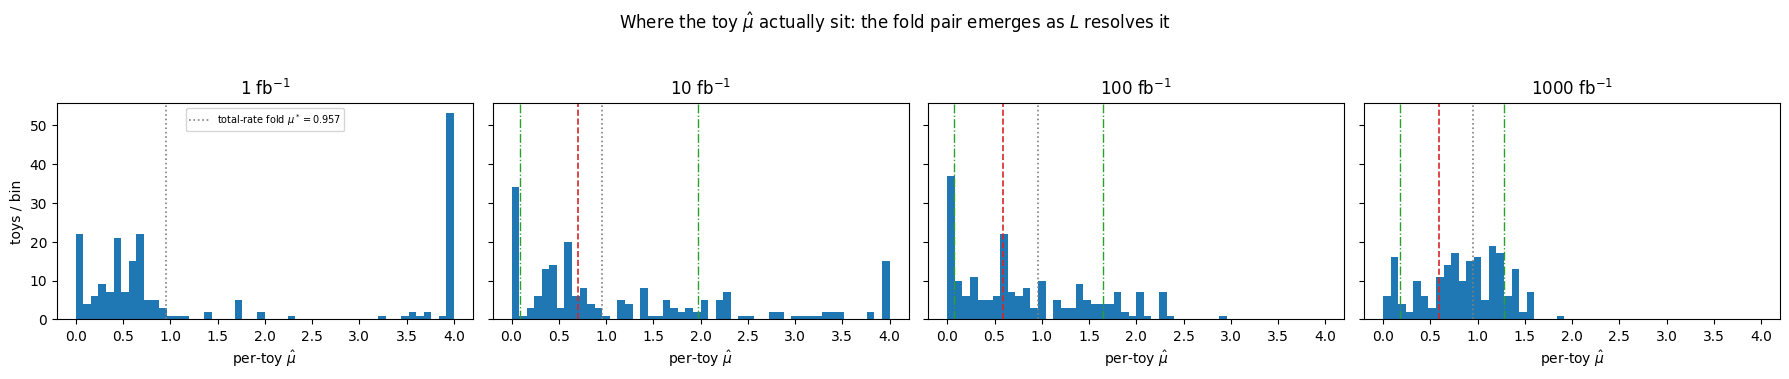

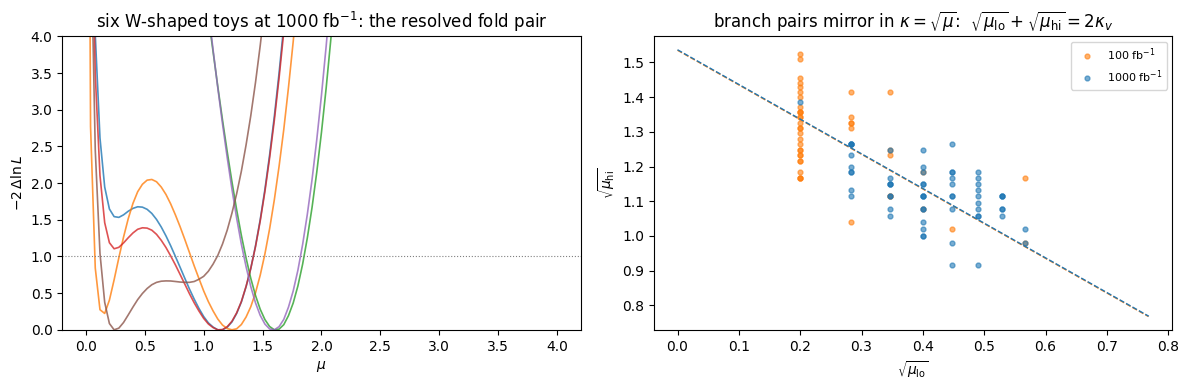

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, L in zip(axes, LUMIS):
    T = results[L]['nll_toys'].numpy().T
    muhat = mu_np[T.argmin(axis=1)]
    ax.hist(muhat, bins=np.arange(0, 4.04, 0.08), color='C0')
    ax.axvline(0.957, color='grey', ls=':', lw=1.2, label=r'total-rate fold $\mu^*=0.957$')
    P = branches[L]
    if len(P) >= 10:
        kv2 = (0.5*(np.sqrt(P[:, 0]) + np.sqrt(P[:, 1])).mean())**2
        ax.axvline(kv2, color='C3', ls='--', lw=1.2, label=r'effective fold $\kappa_v^2$')
        ax.axvline(P[:, 0].mean(), color='C2', ls='-.', lw=1.0, label='branch means')
        ax.axvline(P[:, 1].mean(), color='C2', ls='-.', lw=1.0)
    ax.set_title(f'{L:.0f} fb$^{{-1}}$'); ax.set_xlabel(r'per-toy $\hat\mu$')
axes[0].set_ylabel('toys / bin'); axes[0].legend(fontsize=7)
fig.suptitle(r'Where the toy $\hat\mu$ actually sit: the fold pair emerges as $L$ resolves it', y=1.04)
fig.tight_layout(); plt.show()

fig, (axW, axS) = plt.subplots(1, 2, figsize=(12, 4.0))
T = results[1000.]['nll_toys'].numpy().T
d = np.diff(T, axis=1)
shown = 0
for t in range(len(T)):
    locs = np.where((d[t, :-1] < 0) & (d[t, 1:] > 0))[0] + 1
    if len(locs) >= 2 and shown < 6:
        axW.plot(mu_np, T[t] - T[t].min(), lw=1.2, alpha=0.8)
        shown += 1
axW.axhline(1.0, color='grey', ls=':', lw=0.8)
axW.set_xlabel(r'$\mu$'); axW.set_ylabel(r'$-2\,\Delta\ln L$'); axW.set_ylim(0, 4)
axW.set_title('six W-shaped toys at 1000 fb$^{-1}$: the resolved fold pair')

for L, c in [(100., 'C1'), (1000., 'C0')]:
    P = branches[L]
    axS.plot(np.sqrt(P[:, 0]), np.sqrt(P[:, 1]), 'o', ms=3.5, alpha=0.6, color=c, label=f'{L:.0f} fb$^{{-1}}$')
    kv = 0.5*(np.sqrt(P[:, 0]) + np.sqrt(P[:, 1])).mean()
    x = np.linspace(0, kv, 50)
    axS.plot(x, 2*kv - x, '--', lw=1, color=c)
axS.set_xlabel(r'$\sqrt{\mu_{\rm lo}}$'); axS.set_ylabel(r'$\sqrt{\mu_{\rm hi}}$')
axS.set_title(r'branch pairs mirror in $\kappa=\sqrt{\mu}$:  $\sqrt{\mu_{\rm lo}}+\sqrt{\mu_{\rm hi}} = 2\kappa_v$')
axS.legend(fontsize=8)
fig.tight_layout(); plt.show()

**Resolution — the flag is the fold, seen from a new angle; no bug, no new effect.**

- **Grid-independent.** On $\mu \in [0,8]$ with two independent binnings (`occ_1d`, `ctl_1d`), the same seed-42
  toys give med($\hat\mu$) = 0.65/0.70 and 24.5–25.5% $\le$ 0.24 at 100 fb⁻¹ (vs 0.64 / 27.0% here), and nothing
  at $\mu \ge 4$. The pile-up is physics pressed against the *physical* $\mu \ge 0$ floor, not the $[0,4]$ window.
  (At 1 fb⁻¹ the mechanism is different: the curves are nearly flat — median NLL(1)−NLL(min) is 0.06 — and noise
  minima land on *both* edges, 26% at $\mu = 4$. That is the open-interval regime of §8, not the fold.)
- **It is the fold — but the attractor is the *shape-weighted* fold pair, not the total-rate $\mu^* = 0.957$.**
  The W-shaped toys (0% → 7% → 22% → 31% of toys for $L$ = 1 → 1000) have branches at 0.076 ± 0.066 / 1.65 ± 0.32
  (100 fb⁻¹) and 0.175 ± 0.069 / 1.28 ± 0.20 (1000 fb⁻¹), mirror-symmetric in $\kappa = \sqrt\mu$ about
  $\kappa_v = 0.768$ at both luminosities — an **effective fold at $\mu_{\rm eff} = \kappa_v^2 \approx 0.59$**,
  well below the total-rate fold. That is where this binning's own per-bin folds point: the information-carrying
  high-mass bins fold at $\mu^*_b$ = 0.46–0.68 (`rate_degeneracy`, same axis; the Fisher-weighted vertex lands at
  $\kappa \approx 0.87$), while the total-rate fold at 0.957 is dominated by low-mass bins that carry no shape
  information. `bartlett_correction`'s "$\hat\mu$ attracted toward $\mu^*$" refines to: attracted toward the
  effective fold pair of the full likelihood.
- **The 100 → 1000 fb⁻¹ evolution is branch *resolution*, not disappearance.** At 100 fb⁻¹ the lower branch sits
  at 0.08 ± 0.07 — pressed against $\mu = 0$, hence "27% at/near the boundary" (exactly *at* 0: only 7.5%). At
  1000 fb⁻¹ it detaches (0.18 ± 0.07), the boundary empties (0.0% at 0), and ~13% of toys ($\hat\mu \le 0.24$)
  sit on the resolved lower branch: a bimodal, left-skewed $\hat\mu$ distribution with median 0.92 (the skew
  pulls it below 1; numerically close to the rate-fold mirror of $\mu = 1$, which is 0.915) and mean 0.859 —
  reproducing `bartlett_correction`'s 0.859 ± 0.417 **measured on these same tensors**, and consistent with
  `rate_degeneracy`'s $L^{-1/4}$ scaling and 0.86 low-bias narrative.
- **Consequences.** (i) The `med(mu_toy)` column of §8 is fold-shaped and must **not** be read as a calibration
  bias of the histogram analysis; the curve-level Asimov ≈ median(toys) conclusion is untouched. (ii) The
  under-coverage `bartlett_correction` localises at $\mu_{\rm true} \in \{0.957, 1\}$ (0.59–0.61) is this same
  lower branch escaping the $\Delta = 1$ interval — one mechanism, three notebooks, one consistent picture.
  (iii) Nothing new to fix: this is prong-2's known parametrisation-level fold ($\kappa = \sqrt\mu$ provably
  cannot remove it); the working mitigation remains the prong-3 Neyman construction.